# BLI segment-sum-contribution: prediction + contribution histograms
1. Build `./data/augmented_data.csv`: every distinct molecule in C_paper x 3 hexane : EtOAc ratios (10:1, 4:1, 1:1).
2. Predict Rf and per-fragment contributions.
3. Plot the contribution histogram of 12 functional groups, comparing 10:1 / 4:1 / 1:1.

## Dataset
Distinct molecules are taken from C_paper (case-sensitive exact SMILES match, first occurrence kept; aromatic `c` and aliphatic `C` are different atoms, so spreadsheet tools that ignore case must not be used). Each molecule is paired with hexane/EtOAc at three volume ratios, given as mole fractions.

In [1]:
import pandas as pd

CPAPER_CSV = "./data/Cpaper.csv"
AUGMENTED_CSV = "./data/augmented_data.csv"

# hexane : EtOAc volume ratio -> mole fractions (ratio1 = hexane, ratio2 = EtOAc)
MOLE_RATIOS = [(0.882244, 0.117756),   # 10:1
               (0.749803, 0.250197),   # 4:1
               (0.428314, 0.571686)]   # 1:1

cpaper = pd.read_csv(CPAPER_CSV, encoding="utf-8-sig")
smiles = pd.Series(cpaper["Smiles"].str.strip().unique(), name="Smiles")
print(f"C_paper rows: {len(cpaper)}, distinct molecules: {len(smiles)}")

ratios = pd.DataFrame(MOLE_RATIOS, columns=["ratio1", "ratio2"])
aug = smiles.to_frame().merge(ratios, how="cross")
aug["eluent1_smiles"] = "CCCCCC"
aug["eluent2_smiles"] = "CCOC(C)=O"
aug = aug[["Smiles", "eluent1_smiles", "eluent2_smiles", "ratio1", "ratio2"]]
aug.to_csv(AUGMENTED_CSV, index=False, encoding="utf-8-sig")
print("saved:", AUGMENTED_CSV, aug.shape)

C_paper rows: 14711, distinct molecules: 11486
saved: ./data/augmented_data.csv (34458, 5)


In [2]:
import os
os.environ["TQDM_DISABLE"] = "1"  # silence per-batch progress bars

%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import D4CMPP_TLC
import SSC

In [3]:
INPUT_CSV = "./data/augmented_data.csv"
OUTPUT_CSV = "./data/augmented_data_BLI_segment_sum_contribution_pred.csv"
MODEL_NAME = "BLI_segment_sum_contribution"
BATCH_SIZE = 64

# ratio1 (hexane fraction) -> label, plotted in this order
RATIO_LABELS = {0.882244: '10:1', 0.749803: '4:1', 0.428314: '1:1'}
RATIO_COLORS = {'10:1': 'blue', '4:1': 'green', '1:1': 'red'}

# contribution column used for the histograms
# (hist/*.csv of Figure 7 uses tanh-normalized contributions)
CONTRIB_COL = "normalized_subgroup_contribution"

# (fragment SMILES, panel title) - same panels as hist/plot_hist.ipynb
HIST_GROUPS = [
    ('*CO', 'Hydroxyl'), ('*N', 'Amino'), ('*C#N', 'Nitrile'),
    ('*C(=O)O', 'Carboxyl'), ('*C=O', 'Aldehyde'), ('*[N+](=O)[O-]', 'Nitro'),
    ('c1ccccc1', 'Benzene'), ('*C', 'Methyl'), ('*CCCC', 'Butyl'),
    ('C1CCCCC1', 'Cyclohexane'), ('*CC', 'Ethyl'), ('*C(C)C', 'Isopropyl'),
]

In [4]:
BLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3(MODEL_NAME)

sk_scaler = BLI_segment.scaler.scaler  # sklearn StandardScaler
RF_MEAN = float(sk_scaler.mean_[0])
RF_STD = float(sk_scaler.scale_[0])
print(f"Rf scaler: mean={RF_MEAN:.6f}, std={RF_STD:.6f}")

founded model: ./Trained_models/BLI_segment_sum_contribution
Device: cuda
#params: 184707
Loading params from ./Trained_models/BLI_segment_sum_contribution/final.pth


/home/ainshin/miniconda3/envs/ksw_pyg_dgl/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Sculptor Index: (6, 2, 0)
Rf scaler: mean=0.445887, std=0.232983


In [5]:
df = pd.read_csv(INPUT_CSV, encoding="utf-8-sig")  # file has a BOM
df = df.reset_index(drop=True)
df["ratio_label"] = df["ratio1"].round(6).map(RATIO_LABELS)
assert df["ratio_label"].notna().all(), "ratio1 values not in RATIO_LABELS"
print(df.shape)
print(df["ratio_label"].value_counts())
df.head()

(34458, 6)
ratio_label
10:1    11486
4:1     11486
1:1     11486
Name: count, dtype: int64


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,ratio_label
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,1:1
3,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1
4,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1


## Prediction
`get_score` is called per batch; contributions are split per molecule by `subgroup_size` and checked against `get_fragment()`.

In [6]:
def score_batch(analyzer, batch):
    score = analyzer.get_score(
        Smiles=list(batch["Smiles"]),
        eluent1_smiles=list(batch["eluent1_smiles"]),
        eluent2_smiles=list(batch["eluent2_smiles"]),
        ratio1=[float(x) for x in batch["ratio1"]],
        ratio2=[float(x) for x in batch["ratio2"]],
    )
    y = np.asarray(score["y"], dtype=float).reshape(-1)
    contrib = np.asarray(score["subgroup_contributions"], dtype=float).reshape(-1)
    sizes = np.asarray(score["subgroup_size"]).reshape(-1).astype(int)

    if len(y) != len(batch) or len(sizes) != len(batch):
        raise ValueError(f"Output count ({len(y)}) != input rows ({len(batch)}). Check for invalid SMILES.")
    if sizes.sum() != len(contrib):
        raise ValueError("Sum of subgroup_size != length of subgroup_contributions.")

    offsets = np.concatenate([[0], np.cumsum(sizes)])
    return [(y[i], contrib[offsets[i]:offsets[i + 1]]) for i in range(len(batch))]


frag_cache = {}  # fragments depend only on the molecule SMILES
mol_rows = []
frag_rows = []

for start in range(0, len(df), BATCH_SIZE):
    batch = df.iloc[start:start + BATCH_SIZE]
    results = score_batch(BLI_segment, batch)

    for (row_idx, row), (y_scaled, contribs) in zip(batch.iterrows(), results):
        smi = row["Smiles"]
        if smi not in frag_cache:
            frag_cache[smi] = BLI_segment.get_fragment(smi)
        fragments = frag_cache[smi]
        if len(fragments) != len(contribs):
            raise ValueError(f"row {row_idx}: #fragments({len(fragments)}) != #contributions({len(contribs)}) | {smi}")

        rf_pred = RF_MEAN + RF_STD * y_scaled
        mol_rows.append({"row_id": row_idx, "Rf_pred": rf_pred, "y_scaled": y_scaled, "n_fragments": len(fragments)})

        for frag_idx, (frag, c) in enumerate(zip(fragments, contribs)):
            frag_rows.append({
                "row_id": row_idx,
                "frag_idx": frag_idx,
                "frag_smiles": frag.smiles,
                "frag_atoms": " ".join(str(int(a)) for a in frag.atoms),
                "contribution": c,                               # model output (scaled space)
                "contribution_Rf": RF_STD * c,                   # contribution in Rf units
                "normalized_subgroup_contribution": np.tanh(c),  # [-1, 1]
            })

mol_df = pd.DataFrame(mol_rows)
frag_df = pd.DataFrame(frag_rows)
print(mol_df.shape, frag_df.shape)

(34458, 4) (201450, 7)


## Check
- `sum(contribution) == y_scaled`
- `Rf_pred` equals `analyzer.predict()` for the first rows

In [7]:
check = frag_df.groupby("row_id")["contribution"].sum().to_frame("sum_contrib").join(mol_df.set_index("row_id"))
print("max |sum(contribution) - y_scaled| =", np.abs(check["sum_contrib"] - check["y_scaled"]).max())

for i in range(3):
    r = df.iloc[i]
    p = BLI_segment.predict(
        Smiles=[r["Smiles"]], eluent1_smiles=[r["eluent1_smiles"]], eluent2_smiles=[r["eluent2_smiles"]],
        ratio1=[float(r["ratio1"])], ratio2=[float(r["ratio2"])],
    )
    print(i, float(list(p.values())[0][0]), mol_df.loc[mol_df.row_id == i, "Rf_pred"].item())

max |sum(contribution) - y_scaled| = 6.295740604400635e-07
0 0.5618195533752441 0.5618195794755165


1 0.5387396812438965 0.5387397219480741
2 0.5366290807723999 0.5366290744906136


## Save

In [8]:
out_df = (
    df.rename_axis("row_id").reset_index()
      .merge(mol_df, on="row_id")
      .merge(frag_df, on="row_id")
      .sort_values(["row_id", "frag_idx"])
)
out_df = out_df[[
    "row_id", "Smiles", "eluent1_smiles", "eluent2_smiles", "ratio1", "ratio2", "ratio_label",
    "Rf_pred", "y_scaled", "n_fragments",
    "frag_idx", "frag_smiles", "frag_atoms",
    "contribution", "normalized_subgroup_contribution", "contribution_Rf",
]]
out_df.to_csv(OUTPUT_CSV, index=False)
print("saved:", OUTPUT_CSV, out_df.shape)
out_df.head(10)

saved: ./data/augmented_data_BLI_segment_sum_contribution_pred.csv (201450, 16)


,row_id,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,ratio_label,Rf_pred,y_scaled,n_fragments,frag_idx,frag_smiles,frag_atoms,contribution,normalized_subgroup_contribution,contribution_Rf
0,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1,0.561820,0.497602,3,0,*C=C(*)Br,1 2 0,0.127331,0.126648,0.029666
1,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1,0.561820,0.497602,3,1,c1ccccc1,9 10 11 12 13 14,0.126240,0.125573,0.029412
2,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1,0.561820,0.497602,3,2,C1CSCSC1,3 4 5 6 7 8,0.244031,0.239300,0.056855
3,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1,0.538740,0.398539,3,0,*C=C(*)Br,1 2 0,0.015940,0.015939,0.003714
4,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1,0.538740,0.398539,3,1,c1ccccc1,9 10 11 12 13 14,0.142760,0.141798,0.033261
5,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1,0.538740,0.398539,3,2,C1CSCSC1,3 4 5 6 7 8,0.239839,0.235344,0.055878
6,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,1:1,0.536629,0.389480,3,0,*C=C(*)Br,1 2 0,-0.152757,-0.151580,-0.035590
7,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,1:1,0.536629,0.389480,3,1,c1ccccc1,9 10 11 12 13 14,0.315359,0.305304,0.073473
8,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,1:1,0.536629,0.389480,3,2,C1CSCSC1,3 4 5 6 7 8,0.226879,0.223065,0.052859
9,3,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1,0.476065,0.129528,2,0,OC/C=C\CBr,5 2 3 0 1 4,0.333975,0.322088,0.077810


## Functional-group contribution histograms (10:1, 4:1, 1:1)

In [9]:
hist_data = {
    frag: {lab: out_df.loc[(out_df["frag_smiles"] == frag) & (out_df["ratio_label"] == lab), CONTRIB_COL].values
           for lab in RATIO_COLORS}
    for frag, _ in HIST_GROUPS
}
pd.DataFrame({frag: {lab: len(v) for lab, v in d.items()} for frag, d in hist_data.items()}).T

,10:1,4:1,1:1
*CO,92,92,92
*N,225,225,225
*C#N,553,553,553
*C(=O)O,147,147,147
*C=O,213,213,213
*[N+](=O)[O-],469,469,469
c1ccccc1,15062,15062,15062
*C,7861,7861,7861
*CCCC,83,83,83
C1CCCCC1,304,304,304


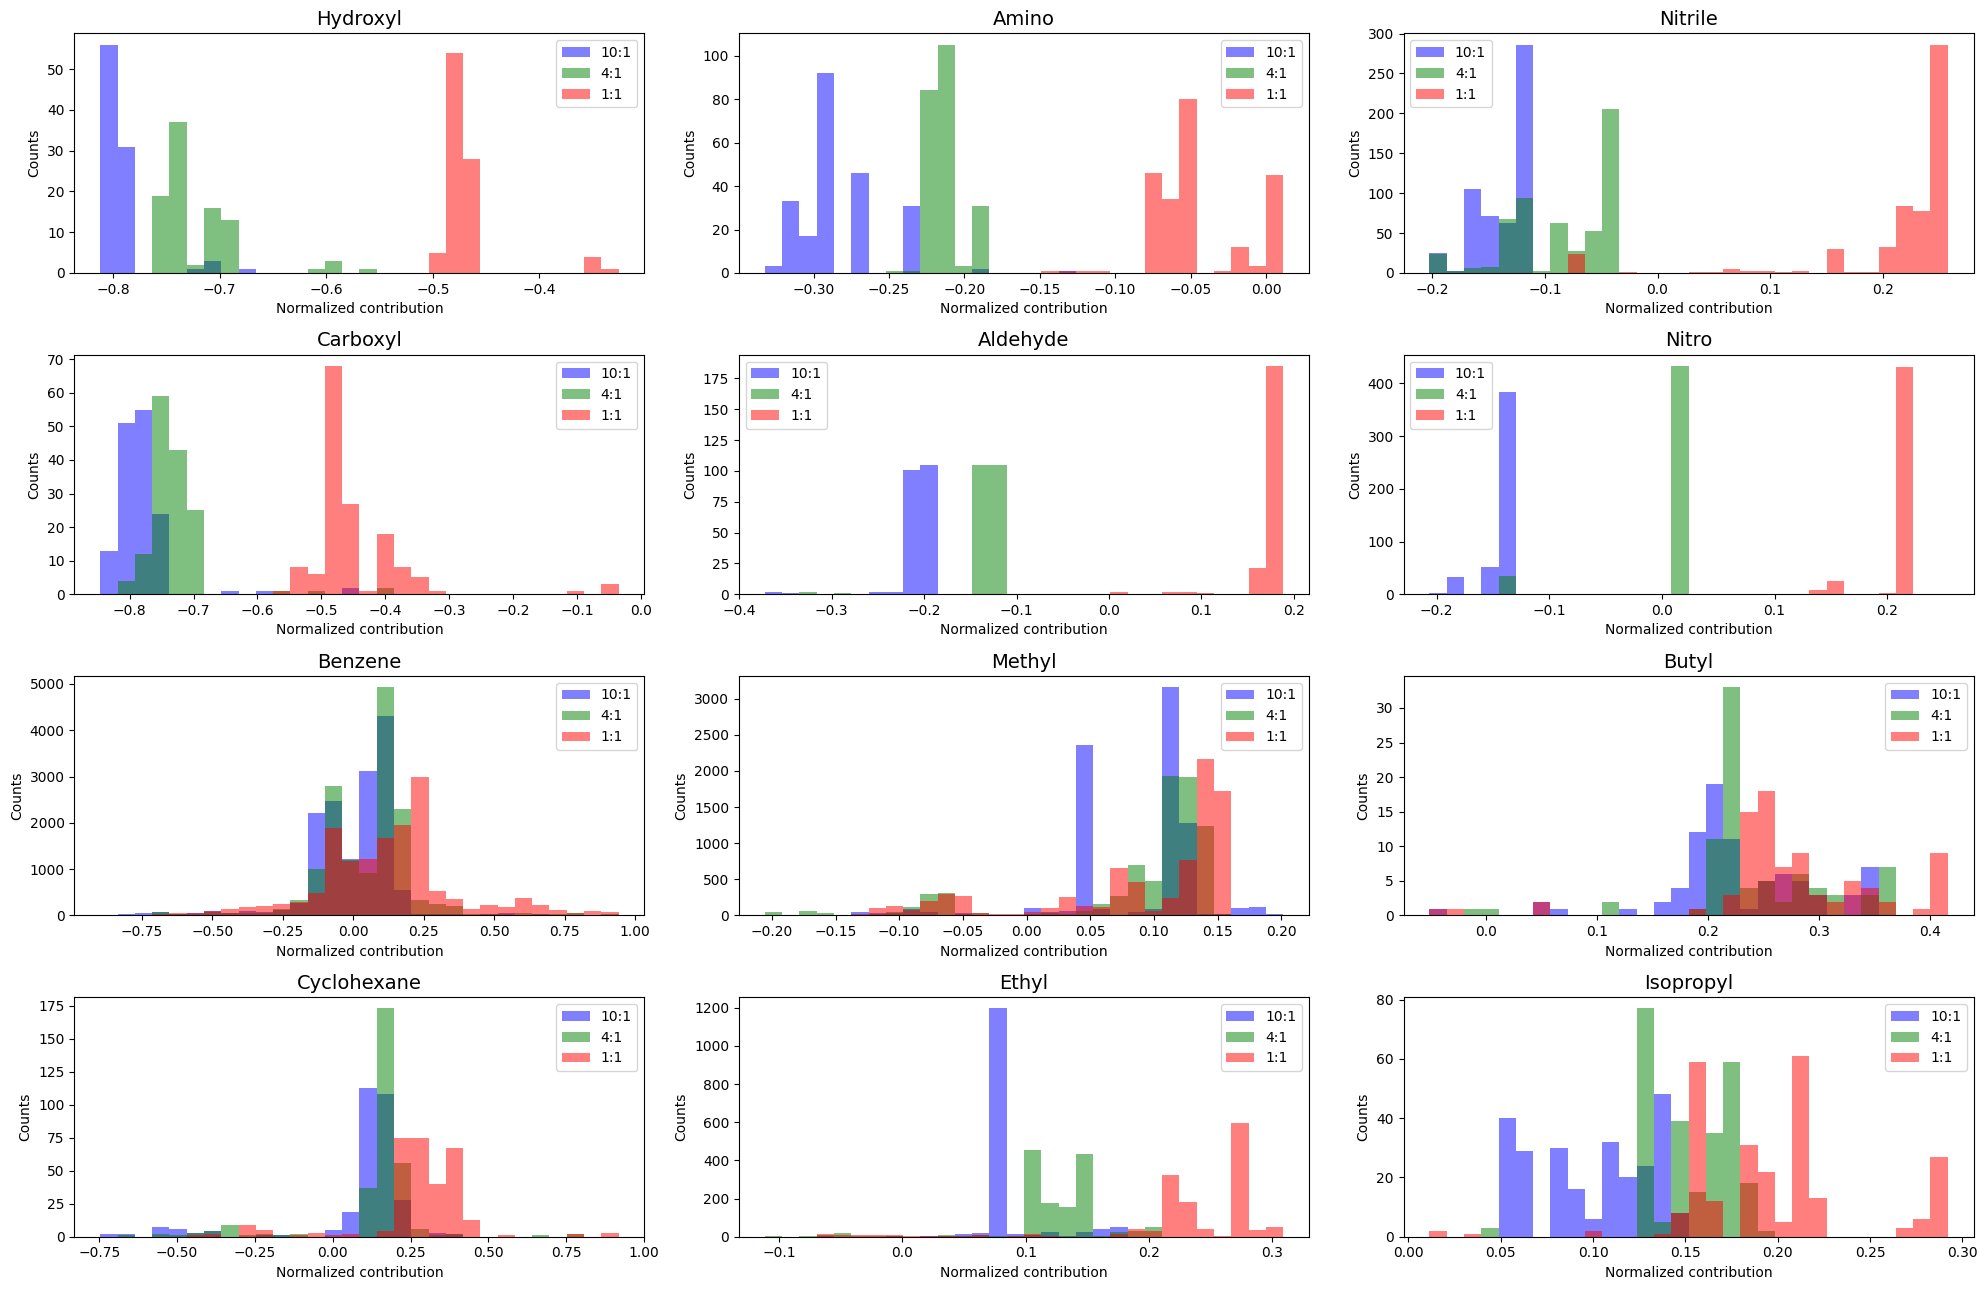

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(20, 13))

for ax, (frag, title) in zip(axes.flat, HIST_GROUPS):
    values = [hist_data[frag][lab] for lab in RATIO_COLORS]
    if sum(len(v) for v in values) == 0:
        ax.set_title(f"{title} (no data)", fontsize=14)
        continue
    bins = np.histogram_bin_edges(np.concatenate(values), bins=30)
    for lab, v in zip(RATIO_COLORS, values):
        ax.hist(v, bins=bins, color=RATIO_COLORS[lab], alpha=0.5, label=lab)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Normalized contribution')
    ax.set_ylabel('Counts')
    ax.legend()

plt.tight_layout()
plt.show()